# Exploratory Data Analysis

Important: the individual cells are mixed thematically – they do not follow the order in which they are executed.

## Database connection

In [1]:
import pandas as pd
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from getpass import getpass

In [83]:
# Connect to the local PostgreSQL database
db_url = URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password=getpass("PostgreSQL password: "),
    host="localhost",
    port=5432,
    database="olist_ecommerce"
)

engine = create_engine(db_url)

PostgreSQL password:  ········


## Monthly distrbution + KPI `late_delivery_rate_pct`

In [3]:
# Verify the connection and access to the delivery view
query = """
SELECT COUNT(*) AS total_orders FROM vw_order_delivery
"""

pd.read_sql(query, engine)

,total_orders
0,99441


In [4]:
# Load order-level data from PostgreSQL
query = """
SELECT
    order_id,
    order_purchase_timestamp,
    order_status
FROM vw_order_delivery
"""

orders_eda = pd.read_sql(query, engine, parse_dates=["order_purchase_timestamp"])

# Check the available date range
print("First order:", orders_eda["order_purchase_timestamp"].min())
print("Last order:", orders_eda["order_purchase_timestamp"].max())

First order: 2016-09-04 21:15:19
Last order: 2018-10-17 17:30:18


In [5]:
# Calculate the number of orders placed each month
monthly_orders = (orders_eda
    .groupby(orders_eda["order_purchase_timestamp"].dt.to_period("M"))
    .size()
    .rename("total_orders")
)

# Display monthly order volumes
display(monthly_orders.to_frame())

,total_orders
order_purchase_timestamp,
2016-09,4
2016-10,324
2016-12,1
2017-01,800
2017-02,1780
2017-03,2682
2017-04,2404
2017-05,3700
2017-06,3245


> designating the period from `January 2017` to `August 2018` as the primary scope for the comparative monthly analysis

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

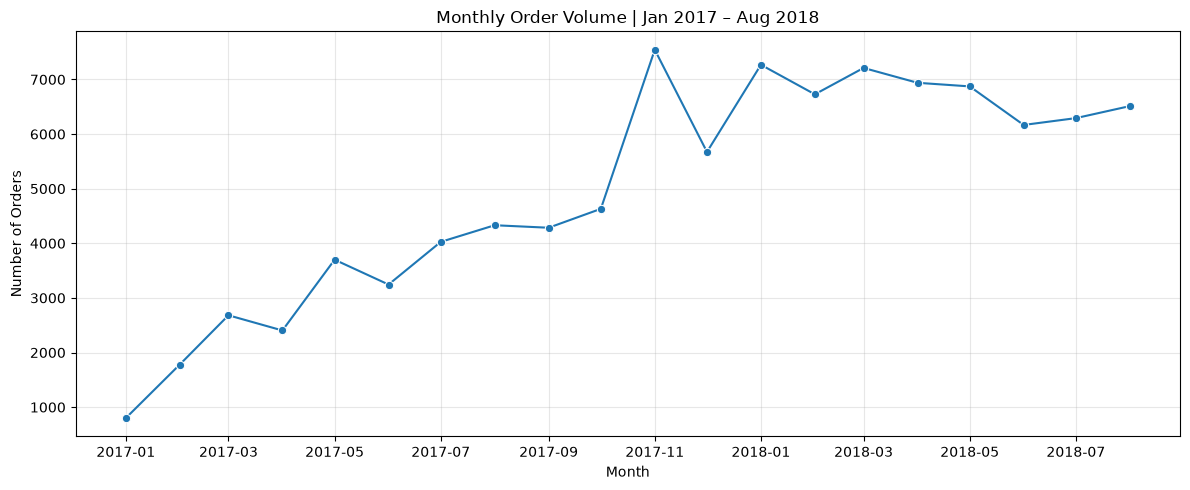

In [12]:
# Select the analysis period
monthly_trend = monthly_orders.loc["2017-01":"2018-08"].reset_index()

# Convert monthly periods to timestamps
monthly_trend["order_purchase_timestamp"] = (monthly_trend["order_purchase_timestamp"].dt.to_timestamp())

# Plot monthly order volume
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_trend,
    x="order_purchase_timestamp",
    y="total_orders",
    marker="o"
)

plt.title("Monthly Order Volume | Jan 2017 – Aug 2018")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# Load delivery performance data for the selected period
query = """
SELECT
    order_purchase_timestamp,
    is_late_delivery
FROM vw_order_delivery
WHERE order_purchase_timestamp >= '2017-01-01'
    AND order_purchase_timestamp < '2018-09-01'
    AND is_late_delivery IS NOT NULL
"""

delivery_eda = pd.read_sql(query, engine, parse_dates=["order_purchase_timestamp"])

delivery_eda.head()

,order_purchase_timestamp,is_late_delivery
0,2017-10-02 10:56:33,False
1,2018-07-24 20:41:37,False
2,2018-08-08 08:38:49,False
3,2017-11-18 19:28:06,False
4,2018-02-13 21:18:39,False


In [10]:
# Create a monthly date column
delivery_eda["month"] = (
    delivery_eda["order_purchase_timestamp"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Calculate the monthly percentage of delayed deliveries
monthly_late_rate = (
    delivery_eda.groupby("month")["is_late_delivery"]
    .mean()
    .mul(100)
    .reset_index(name="late_delivery_rate_pct")
)

display(monthly_late_rate)

,month,late_delivery_rate_pct
0,2017-01-01,2.933333
1,2017-02-01,2.964307
2,2017-03-01,4.556167
3,2017-04-01,6.556665
4,2017-05-01,2.990127
5,2017-06-01,3.030303
6,2017-07-01,2.789256
7,2017-08-01,2.909611
8,2017-09-01,4.385542
9,2017-10-01,4.175971


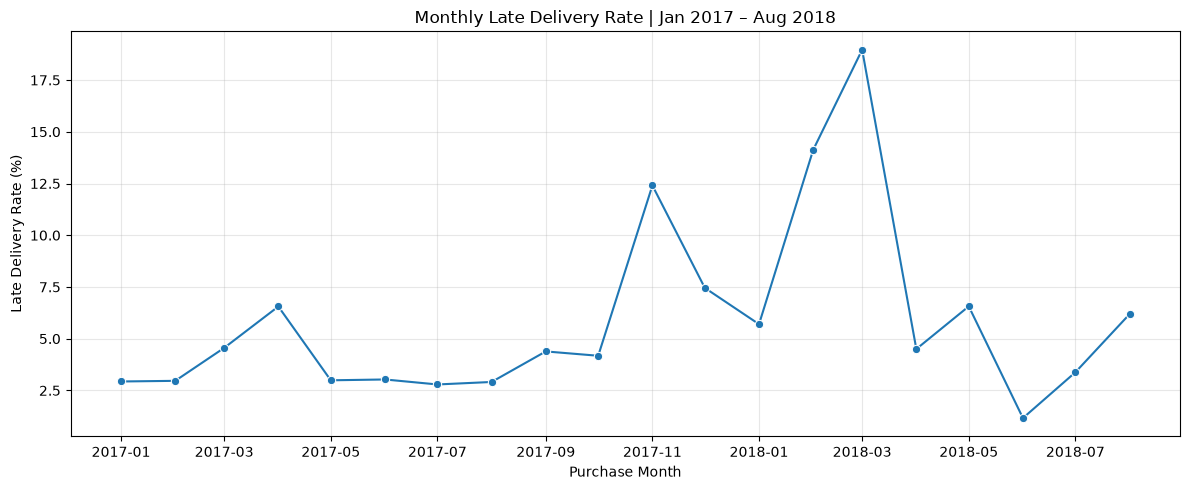

In [13]:
# Plot monthly late delivery rates
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_late_rate,
    x="month",
    y="late_delivery_rate_pct",
    marker="o"
)

plt.title("Monthly Late Delivery Rate | Jan 2017 – Aug 2018")
plt.xlabel("Purchase Month")
plt.ylabel("Late Delivery Rate (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
# Prepare monthly order volume data
orders_plot = monthly_trend.rename(columns={"order_purchase_timestamp": "month"})

# Merge order volume and late delivery rate into one DataFrame
combined_monthly = orders_plot.merge(
    monthly_late_rate,
    on="month",
    how="inner"
)

# Display the combined data
display(combined_monthly)

,month,total_orders,late_delivery_rate_pct
0,2017-01-01,800,2.933333
1,2017-02-01,1780,2.964307
2,2017-03-01,2682,4.556167
3,2017-04-01,2404,6.556665
4,2017-05-01,3700,2.990127
5,2017-06-01,3245,3.030303
6,2017-07-01,4026,2.789256
7,2017-08-01,4331,2.909611
8,2017-09-01,4285,4.385542
9,2017-10-01,4631,4.175971


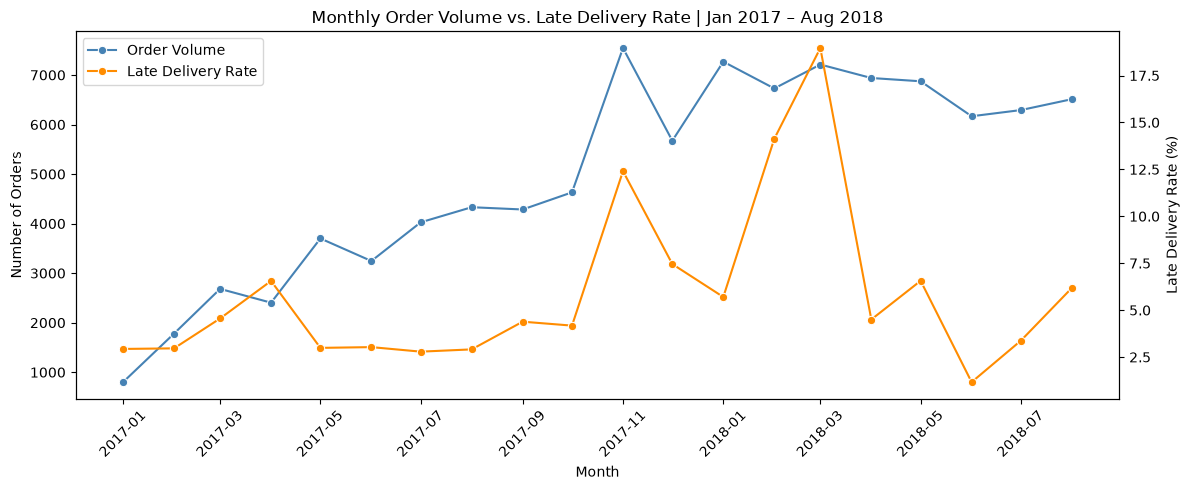

In [19]:
# Create the figure and the first axis
fig, ax1 = plt.subplots(figsize=(12, 5))

# Plot monthly order volume
sns.lineplot(
    data=combined_monthly,
    x="month",
    y="total_orders",
    color="steelblue",
    marker="o",
    label="Order Volume",
    ax=ax1
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Number of Orders")
ax1.tick_params(axis="x", rotation=45)

# Create the second y-axis
ax2 = ax1.twinx()

# Plot monthly late delivery rate
sns.lineplot(
    data=combined_monthly,
    x="month",
    y="late_delivery_rate_pct",
    color="darkorange",
    marker="o",
    label="Late Delivery Rate",
    ax=ax2
)

ax2.set_ylabel("Late Delivery Rate (%)")

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left"
)

# Remove the separate legend from the second axis
if ax2.get_legend() is not None:
    ax2.get_legend().remove()

# Format the chart
plt.title("Monthly Order Volume vs. Late Delivery Rate | Jan 2017 – Aug 2018")
plt.tight_layout()
plt.show()

> An increase in the number of orders does not always correlate with an increase in the percentage of delays. While both initially rise in tandem, from March 2018 onwards, it becomes clear that delays account for a smaller share, despite a high volume of orders. Looks like things are being brought under control?

In [30]:
# Calculate monthly delivery statistics
monthly_delivery = (delivery_eda.groupby("month").agg(evaluated_orders=("is_late_delivery", "size"), late_orders=("is_late_delivery", "sum")).reset_index())

# Add total monthly order volume
monthly_delivery = monthly_delivery.merge(combined_monthly[["month", "total_orders"]], on="month", how="left")

# Calculate monthly late delivery rates
monthly_delivery["late_delivery_rate_pct"] = (monthly_delivery["late_orders"] / monthly_delivery["evaluated_orders"] * 100).round(2)

# Calculate monthly evaluated delivery rates
monthly_delivery["delivery_evaluation_coverage_pct"] = (monthly_delivery["evaluated_orders"] / monthly_delivery["total_orders"] * 100).round(2)

# Arrange columns
monthly_delivery = monthly_delivery[["month", "total_orders", "evaluated_orders", "delivery_evaluation_coverage_pct", "late_orders", "late_delivery_rate_pct"]]

# Display the months with the highest late delivery rates
display(monthly_delivery.sort_values("late_delivery_rate_pct", ascending=False).head(5))

display(monthly_delivery["delivery_evaluation_coverage_pct"].min())
display(monthly_delivery["delivery_evaluation_coverage_pct"].max())

,month,total_orders,evaluated_orders,delivery_evaluation_coverage_pct,late_orders,late_delivery_rate_pct
14,2018-03-01,7211,7003,97.12,1328,18.96
13,2018-02-01,6728,6555,97.43,926,14.13
10,2017-11-01,7544,7288,96.61,904,12.40
11,2017-12-01,5673,5513,97.18,411,7.46
16,2018-05-01,6873,6749,98.20,443,6.56


np.float64(92.87)

np.float64(98.85)

> High Late Delivery Rate values ​​are not a result of a small sample size.

## Delivery by state

**Were the delays in March 2018 concentrated in specific states in Brazil?**

In [31]:
# Load March 2018 delivery data with customer locations
query = """
SELECT
    c.customer_state,
    d.is_late_delivery
FROM vw_order_delivery d
JOIN customers c
    ON d.customer_id = c.customer_id
WHERE d.order_purchase_timestamp >= '2017-01-01'
    AND d.order_purchase_timestamp < '2018-09-01'
    AND d.is_late_delivery IS NOT NULL
"""

delivery_by_state = pd.read_sql(query, engine, parse_dates=["order_purchase_timestamp"])

In [32]:
# Calculate delivery performance by customer state
state_delivery = (
    delivery_by_state.groupby("customer_state")["is_late_delivery"]
    .agg(evaluated_orders="size", late_orders="sum")
    .reset_index()
)

# Calculate the percentage of delayed deliveries
state_delivery["late_delivery_rate_pct"] = (state_delivery["late_orders"] / state_delivery["evaluated_orders"] * 100).round(2)

# Show states with at least 50 evaluated orders
display(
    state_delivery[state_delivery["evaluated_orders"] >= 50]
    .sort_values("late_delivery_rate_pct", ascending=False)
)

,customer_state,evaluated_orders,late_orders,late_delivery_rate_pct
1,AL,396,85,21.46
9,MA,713,125,17.53
24,SE,332,51,15.36
16,PI,475,66,13.89
5,CE,1273,176,13.83
4,BA,3253,396,12.17
18,RJ,12310,1495,12.14
13,PA,942,106,11.25
7,ES,1992,214,10.74
14,PB,516,54,10.47


> Delivery performance varies considerably across Brazilian states. A geographical analysis in `Power BI` will be used to investigate regional patterns and their evolution over time.

**Do shipments between different Brazilian states take longer and experience more frequent delays than shipments within the same state?**

In [75]:
# Load delivery data for single-seller orders
query = """
SELECT DISTINCT
    d.order_id,
    CASE
        WHEN c.customer_state = s.seller_state THEN 'Same-State'
        ELSE 'Interstate'
    END AS delivery_route,
    d.delivery_days,
    d.is_late_delivery,
    d.order_estimated_delivery_date::date
        - d.order_purchase_timestamp::date AS estimated_delivery_days
FROM vw_order_delivery d
JOIN vw_order_sales os
    ON d.order_id = os.order_id
    AND os.seller_count = 1
JOIN order_items oi
    ON d.order_id = oi.order_id
JOIN sellers s
    ON oi.seller_id = s.seller_id
JOIN customers c
    ON d.customer_id = c.customer_id
WHERE d.order_purchase_timestamp >= '2017-01-01'
    AND d.order_purchase_timestamp < '2018-09-01'
    AND d.is_late_delivery IS NOT NULL
"""

route_data = pd.read_sql(query, engine)

In [76]:
# Compare delivery performance by route type
route_summary = (
    route_data.groupby("delivery_route")
    .agg(
        evaluated_orders=("order_id", "count"),
        mean_delivery_days=("delivery_days", "mean"),
        median_delivery_days=("delivery_days", "median"),
        median_estimated_days=("estimated_delivery_days", "median"),
        late_delivery_rate_pct=("is_late_delivery", lambda x: x.mean() * 100)
    )
    .round(2)
)

display(route_summary)

,evaluated_orders,mean_delivery_days,median_delivery_days,median_estimated_days,late_delivery_rate_pct
delivery_route,,,,,
Interstate,60782,15.13,13.0,27.0,8.16
Same-State,34149,7.88,7.0,18.0,4.57


In [78]:
from scipy.stats import mannwhitneyu, chi2_contingency

# Compare delivery times between route types
interstate = route_data.loc[route_data["delivery_route"] == "Interstate", "delivery_days"]
same_state = route_data.loc[route_data["delivery_route"] == "Same-State", "delivery_days"]

u_stat, p_time = mannwhitneyu(interstate, same_state, alternative="two-sided")

print(f"Mann-Whitney U p-value: {p_time:.5F}")

Mann-Whitney U p-value: 0.00000


In [79]:
# Test association between route type and late delivery
contingency_table = pd.crosstab(route_data["delivery_route"], route_data["is_late_delivery"])

chi2_stat, p_late, dof, expected = chi2_contingency(contingency_table)

print(f"Chi-square p-value: {p_late:.5F}")

Chi-square p-value: 0.00000


In [80]:
# Calculate effect sizes for both statistical tests
rank_biserial = 2 * u_stat / (len(interstate) * len(same_state)) - 1
cramers_v = (chi2_stat / len(route_data)) ** 0.5

print(f"Rank-biserial correlation: {rank_biserial:.3f}")
print(f"Cramér's V: {cramers_v:.3f}")

Rank-biserial correlation: 0.596
Cramér's V: 0.068


> Interstate deliveries take much longer and are more frequently delayed.

> Delivery route type is strongly associated with delivery duration but is a relatively weak standalone indicator of delivery delays.

### Distance vs. Delivery Performance

In [86]:
# Inspect the geolocation view
display(pd.read_sql("SELECT * FROM vw_geolocation_prefix LIMIT 5", engine))

,geolocation_zip_code_prefix,latitude_mdn,longitude_mdn,location_count,has_state_conflict
0,01001,-23.550381,-46.634027,26,False
1,01002,-23.548551,-46.635072,13,False
2,01003,-23.548977,-46.635313,17,False
3,01004,-23.549535,-46.634771,22,False
4,01005,-23.549612,-46.636532,25,False


In [88]:
# Load delivery data with customer and seller coordinates
query = """
SELECT
    d.order_id,
    d.delivery_days,
    d.is_late_delivery,
    d.order_estimated_delivery_date::date
        - d.order_purchase_timestamp::date AS estimated_delivery_days,
    gc.latitude_mdn AS customer_lat,
    gc.longitude_mdn AS customer_lon,
    gs.latitude_mdn AS seller_lat,
    gs.longitude_mdn AS seller_lon
FROM vw_order_delivery d
JOIN vw_order_sales os
    ON d.order_id = os.order_id
    AND os.seller_count = 1
JOIN (
    SELECT DISTINCT order_id, seller_id
    FROM order_items
) oi
    ON d.order_id = oi.order_id
JOIN customers c
    ON d.customer_id = c.customer_id
JOIN sellers s
    ON oi.seller_id = s.seller_id
LEFT JOIN vw_geolocation_prefix gc
    ON c.customer_zip_code_prefix = gc.geolocation_zip_code_prefix
LEFT JOIN vw_geolocation_prefix gs
    ON s.seller_zip_code_prefix = gs.geolocation_zip_code_prefix
WHERE d.order_purchase_timestamp >= '2017-01-01'
    AND d.order_purchase_timestamp < '2018-09-01'
    AND d.is_late_delivery IS NOT NULL
"""

distance_data = pd.read_sql(query, engine)

> **Calculating distance — Haversine** <br>
> The Haversine formula allows for the calculation of the distance between two points on the Earth's surface, taking its curvature into account.<br>
> `6371` to przybliżony promień Ziemi w kilometrach.

In [89]:
import numpy as np

# Convert coordinates from degrees to radians
lat1 = np.radians(distance_data["seller_lat"])
lon1 = np.radians(distance_data["seller_lon"])
lat2 = np.radians(distance_data["customer_lat"])
lon2 = np.radians(distance_data["customer_lon"])

# Calculate distances using the Haversine formula
dlat = lat2 - lat1
dlon = lon2 - lon1

a = (np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2)

distance_data["distance_km"] = (2 * 6371 * np.arcsin(np.sqrt(a)))

In [90]:
# Check geographical data coverage
print(f"Total orders: {len(distance_data)}")
print(f"Missing distances: {distance_data['distance_km'].isna().sum()}")

# Summarize estimated distances
display(
    distance_data["distance_km"]
    .describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])
    .round(2)
)

Total orders: 94931
Missing distances: 470


count    94461.00
mean       601.20
std        595.11
min          0.00
50%        433.94
75%        798.98
90%       1458.89
95%       2097.72
99%       2483.55
max       8677.86
Name: distance_km, dtype: float64

> The coordinates are derived from postal codes and are approximate values. Calculate the straight-line distance, not the actual length of the transport route.

> A maximum of 8,677.86 km seems suspicious for a delivery within Brazil. It might point to an issue with the coordinates.

In [91]:
from scipy.stats import spearmanr

# Keep orders with complete data for correlation analysis
distance_valid = distance_data.dropna(
    subset=[
        "distance_km",
        "delivery_days",
        "estimated_delivery_days",
        "is_late_delivery"
    ]
)

# Calculate Spearman correlations and p-values
results = []

for column in [
    "delivery_days",
    "estimated_delivery_days",
    "is_late_delivery"
]:
    rho, p_value = spearmanr(
        distance_valid["distance_km"],
        distance_valid[column]
    )

    results.append({
        "variable": column,
        "spearman_rho": rho,
        "p_value": p_value
    })

display(pd.DataFrame(results))

,variable,spearman_rho,p_value
0,delivery_days,0.543315,0.000000e+00
1,estimated_delivery_days,0.622588,0.000000e+00
2,is_late_delivery,0.069981,7.418753e-103


> Distance is clearly linked to delivery time, but has a much weaker connection to the actual risk of a delay.

> Distance is more strongly correlated with the estimated delivery time (0.623) than with the actual delivery time (0.543) — this indicates that distance was an important factor in determining estimated delivery times.

In [92]:
# Group orders by estimated shipping distance
distance_valid = distance_valid.copy()

distance_valid["distance_band"] = pd.cut(
    distance_valid["distance_km"],
    bins=[0, 100, 300, 600, 1000, 2000, float("inf")],
    labels=["0–100", "100–300", "300–600", "600–1000", "1000–2000", "2000+"],
    include_lowest=True
)

# Calculate delivery performance for each distance band
distance_summary = (
    distance_valid.groupby("distance_band", observed=True)
    .agg(
        evaluated_orders=("is_late_delivery", "size"),
        median_delivery_days=("delivery_days", "median"),
        median_estimated_days=("estimated_delivery_days", "median"),
        late_delivery_rate_pct=("is_late_delivery", lambda x: x.mean() * 100)
    )
    .round(2)
)

display(distance_summary)

,evaluated_orders,median_delivery_days,median_estimated_days,late_delivery_rate_pct
distance_band,,,,
0–100,17651,5.0,15.0,4.52
100–300,13117,8.0,21.0,5.25
300–600,30947,10.0,24.0,6.85
600–1000,17609,13.0,27.0,7.21
1000–2000,9584,15.0,30.0,9.63
2000+,5553,18.0,34.0,12.16


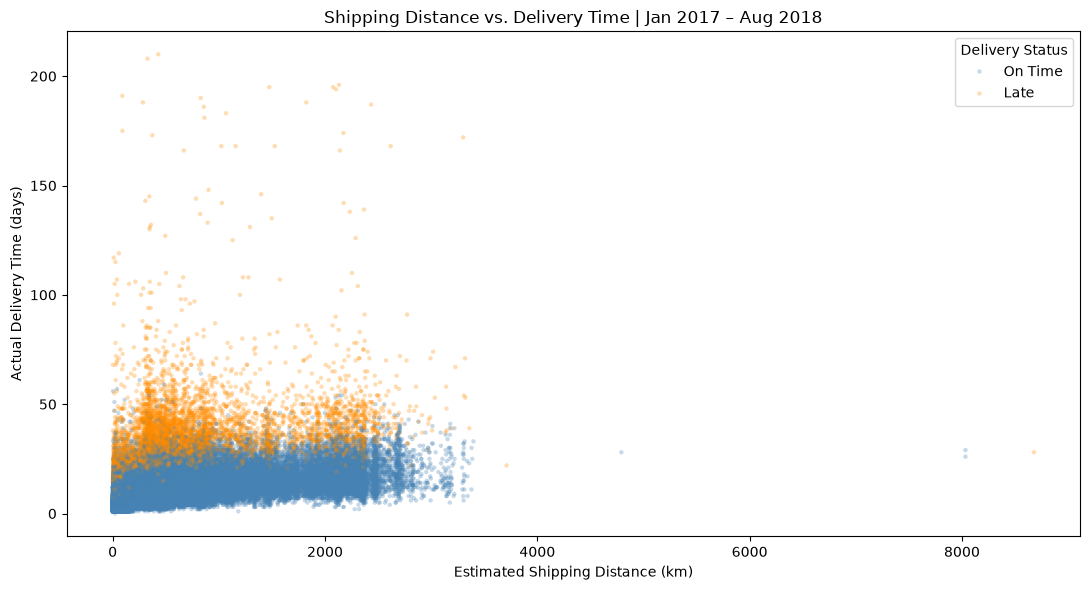

In [96]:
# Assign delivery status labels
distance_valid["delivery_status"] = distance_valid["is_late_delivery"].map({
    False: "On Time",
    True: "Late"
})

# Visualize shipping distance vs. actual delivery time
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=distance_valid,
    x="distance_km",
    y="delivery_days",
    hue="delivery_status",
    hue_order=["On Time", "Late"],
    palette={"On Time": "steelblue", "Late": "darkorange"},
    alpha=0.3
,
    s=10,
    linewidth=0
)

plt.title("Shipping Distance vs. Delivery Time | Jan 2017 – Aug 2018")
plt.xlabel("Estimated Shipping Distance (km)")
plt.ylabel("Actual Delivery Time (days)")
plt.legend(title="Delivery Status")
plt.tight_layout()
plt.show()

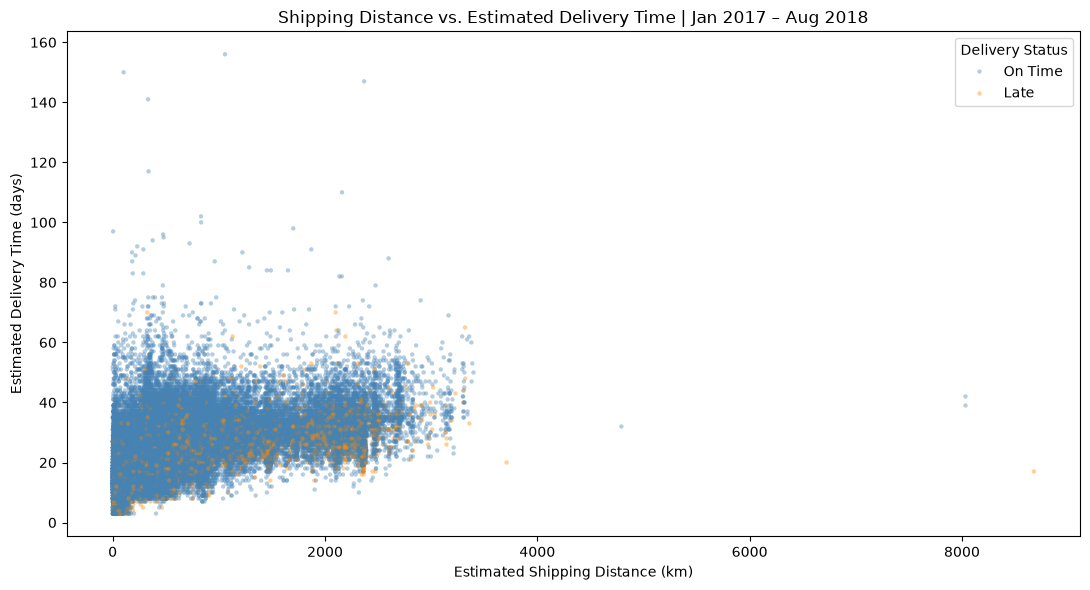

In [98]:
# Visualize shipping distance vs. estimated delivery time
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=distance_valid,
    x="distance_km",
    y="estimated_delivery_days",
    hue="delivery_status",
    hue_order=["On Time", "Late"],
    palette={"On Time": "steelblue", "Late": "darkorange"},
    alpha=0.4,
    s=10,
    linewidth=0
)

plt.title("Shipping Distance vs. Estimated Delivery Time | Jan 2017 – Aug 2018")
plt.xlabel("Estimated Shipping Distance (km)")
plt.ylabel("Estimated Delivery Time (days)")
plt.legend(title="Delivery Status")
plt.tight_layout()
plt.show()

## Delivery Time Analysis

> How long does it actually take to deliver an order, and how does this duration compare to the timeframe promised to the customer?<BR>
> A longer estimated timeframe does not eliminate the problem of delays.

### Distribution

In [34]:
# Load actual delivery times for the analysis period
query = """
SELECT delivery_days
FROM vw_order_delivery
WHERE order_purchase_timestamp >= '2017-01-01'
    AND order_purchase_timestamp < '2018-09-01'
    AND is_late_delivery IS NOT NULL
    AND delivery_days IS NOT NULL
"""

delivery_time = pd.read_sql(query, engine)

In [35]:
# Summarize actual delivery times
display(
    delivery_time["delivery_days"]
    .describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])
    .round(2)
)

count    96203.00
mean        12.48
std          9.54
min          0.00
50%         10.00
75%         16.00
90%         23.00
95%         29.00
99%         46.00
max        210.00
Name: delivery_days, dtype: float64

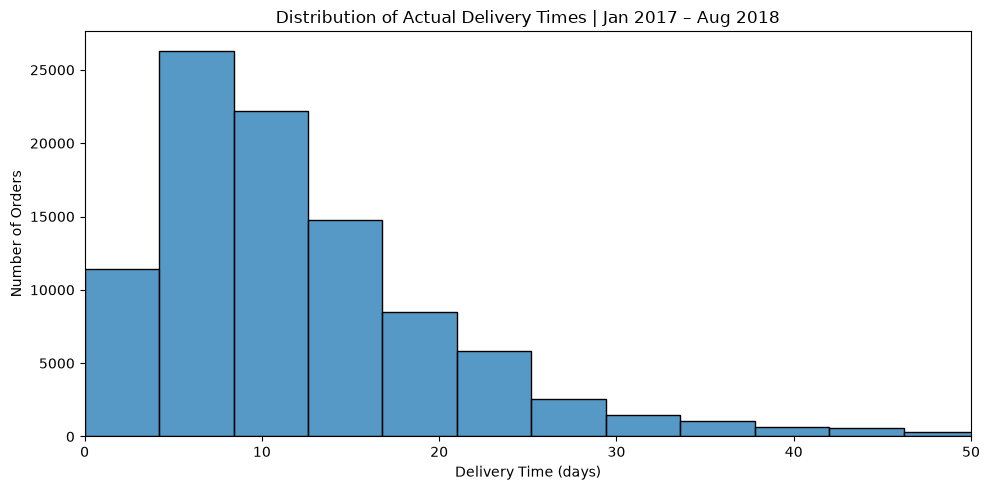

In [44]:
# Visualize the distribution of actual delivery times (~99% of cases)
plt.figure(figsize=(10, 5))

sns.histplot(
    data=delivery_time,
    x="delivery_days",
    bins=50
)
plt.xlim(0, 50)

plt.title("Distribution of Actual Delivery Times | Jan 2017 – Aug 2018")
plt.xlabel("Delivery Time (days)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

In [42]:
display(delivery_time["delivery_days"].sort_values(ascending = False).head(15))

18977    210
53819    208
59622    196
86224    195
68021    195
37264    194
11043    191
78745    190
66532    188
52721    188
60272    187
30215    186
71718    183
64248    181
39523    175
Name: delivery_days, dtype: int64

### Actual vs. Estimated Delivery Time

In [45]:
# Load actual and estimated delivery times
query = """
SELECT
    delivery_days AS actual_delivery_days,
    order_estimated_delivery_date::date
        - order_purchase_timestamp::date AS estimated_delivery_days
FROM vw_order_delivery
WHERE order_purchase_timestamp >= '2017-01-01'
    AND order_purchase_timestamp < '2018-09-01'
    AND is_late_delivery IS NOT NULL
    AND delivery_days IS NOT NULL
"""

delivery_comparison = pd.read_sql(query, engine)

In [46]:
# Compare actual and estimated delivery times
display(delivery_comparison.describe(percentiles=[0.5, 0.75, 0.9, 0.95]).round(2))

,actual_delivery_days,estimated_delivery_days
count,96203.00,96203.00
mean,12.48,24.28
std,9.54,8.60
min,0.00,3.00
50%,10.00,24.00
75%,16.00,29.00
90%,23.00,35.00
95%,29.00,39.00
max,210.00,156.00


In [47]:
# Calculate the difference between estimated and actual delivery time
delivery_comparison["delivery_margin_days"] = (delivery_comparison["estimated_delivery_days"] - delivery_comparison["actual_delivery_days"])

# Examine the distribution of delivery margins
display(delivery_comparison["delivery_margin_days"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).round(2))

count    96203.00
mean        11.81
std         10.09
min       -188.00
50%         12.00
75%         17.00
90%         22.00
95%         26.00
99%         35.00
max        147.00
Name: delivery_margin_days, dtype: float64

> An extreme case of early delivery—147 days ahead of schedule? A mistake?

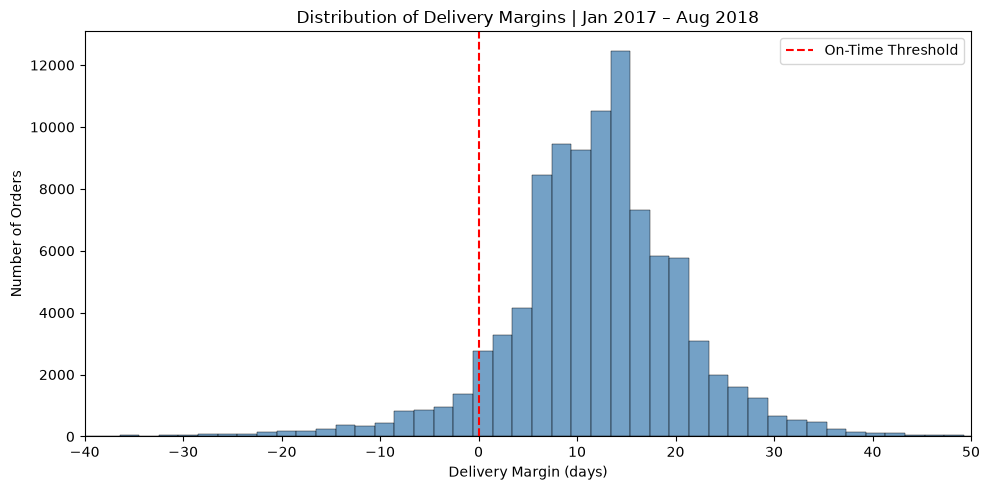

In [49]:
# Visualize the distribution of delivery margins
plt.figure(figsize=(10, 5))

sns.histplot(
    data=delivery_comparison,
    x="delivery_margin_days",
    binwidth=2,
    color="steelblue"
)

# Mark the boundary between late and on-time deliveries
plt.axvline(0, color="red", linestyle="--", label="On-Time Threshold")

plt.xlim(-40, 50)

plt.title("Distribution of Delivery Margins | Jan 2017 – Aug 2018")
plt.xlabel("Delivery Margin (days)")
plt.ylabel("Number of Orders")
plt.legend()
plt.tight_layout()
plt.show()

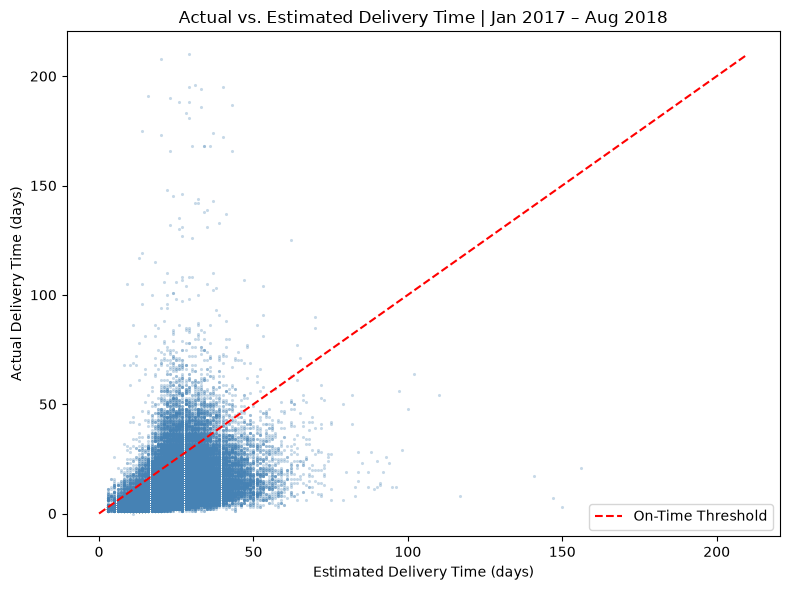

In [61]:
# Sample orders for a readable scatterplot
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=delivery_comparison,
    x="estimated_delivery_days",
    y="actual_delivery_days",
    alpha=0.3,
    s=5,
    color="steelblue",
    linewidth=0
)

# Mark the boundary between early and late deliveries
plt.plot([0, 210], [0, 210], "r--", label="On-Time Threshold")

plt.title("Actual vs. Estimated Delivery Time | Jan 2017 – Aug 2018")
plt.xlabel("Estimated Delivery Time (days)")
plt.ylabel("Actual Delivery Time (days)")
plt.legend()
plt.tight_layout()
plt.show()

In [62]:
### outlieras testing - IQR method

In [63]:
# Detect potential outliers using the IQR method
results = []

for column in ["actual_delivery_days", "delivery_margin_days"]:

    q1 = delivery_comparison[column].quantile(0.25)
    q3 = delivery_comparison[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (delivery_comparison[column] < lower_bound) |
        (delivery_comparison[column] > upper_bound)
    )

    results.append({
        "metric": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outliers.sum(),
        "outlier_pct": outliers.mean() * 100
    })

display(pd.DataFrame(results).round(2))

,metric,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_pct
0,actual_delivery_days,7.0,16.0,9.0,-6.5,29.5,4679,4.86
1,delivery_margin_days,7.0,17.0,10.0,-8.0,32.0,4112,4.27


> I am deferring the analysis of outliers until the predictive modeling stage. For now, I am keeping all observations, and we will continue with the EDA.

In [67]:
# Calculate Spearman correlation between estimated and actual delivery times
from scipy.stats import spearmanr

# Calculate Spearman correlation and p-value
rho, p_value = spearmanr(delivery_comparison["estimated_delivery_days"], delivery_comparison["actual_delivery_days"])

print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.5f}")

Spearman correlation: 0.522
P-value: 0.00000


> Orders with a longer estimated delivery time typically also have a longer actual delivery time. Moderate strength. 

## HEATMAP

In [69]:
# Load order-level features and delivery performance
query = """
SELECT
    d.is_late_delivery,
    d.order_estimated_delivery_date::date
        - d.order_purchase_timestamp::date AS estimated_delivery_days,
    s.item_count,
    s.seller_count,
    s.product_value,
    s.freight_value,
    s.order_value
FROM vw_order_delivery d
LEFT JOIN vw_order_sales s
    ON d.order_id = s.order_id
WHERE d.order_purchase_timestamp >= '2017-01-01'
    AND d.order_purchase_timestamp < '2018-09-01'
    AND d.is_late_delivery IS NOT NULL
"""

correlation_data = pd.read_sql(query, engine)

# Convert the binary target to numeric values
correlation_data["is_late_delivery"] = (correlation_data["is_late_delivery"].astype(int))

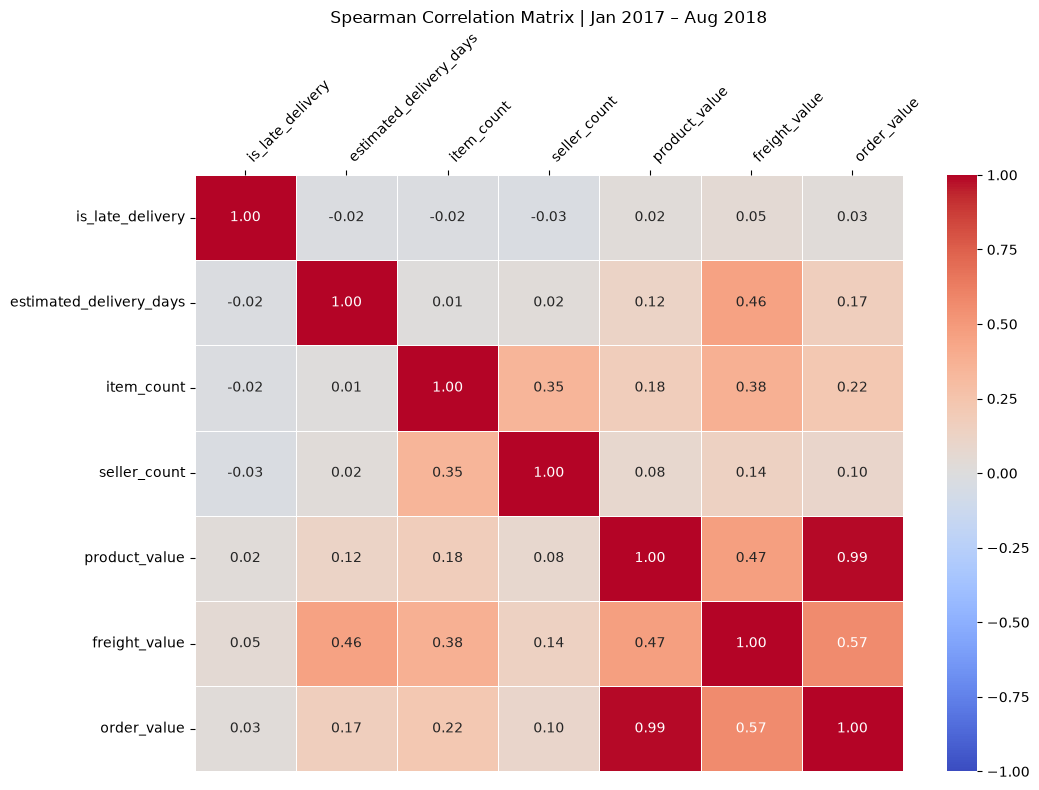

In [71]:
# Calculate Spearman correlation matrix
corr_matrix = correlation_data.corr(method="spearman")

# Visualize correlations
plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.gca().xaxis.tick_top()
plt.xticks(rotation=45, ha="left")

plt.title("Spearman Correlation Matrix | Jan 2017 – Aug 2018")
plt.tight_layout()
plt.show()

In [72]:
# Load order-level features and delivery times
query = """
SELECT
    d.is_late_delivery,
    d.delivery_days AS actual_delivery_days,
    d.order_estimated_delivery_date::date
        - d.order_purchase_timestamp::date AS estimated_delivery_days,
    s.item_count,
    s.seller_count,
    s.product_value,
    s.freight_value,
    s.order_value
FROM vw_order_delivery d
LEFT JOIN vw_order_sales s
    ON d.order_id = s.order_id
WHERE d.order_purchase_timestamp >= '2017-01-01'
    AND d.order_purchase_timestamp < '2018-09-01'
    AND d.is_late_delivery IS NOT NULL
"""

correlation_data = pd.read_sql(query, engine)

# Convert the binary target to numeric values
correlation_data["is_late_delivery"] = (correlation_data["is_late_delivery"].astype(int))

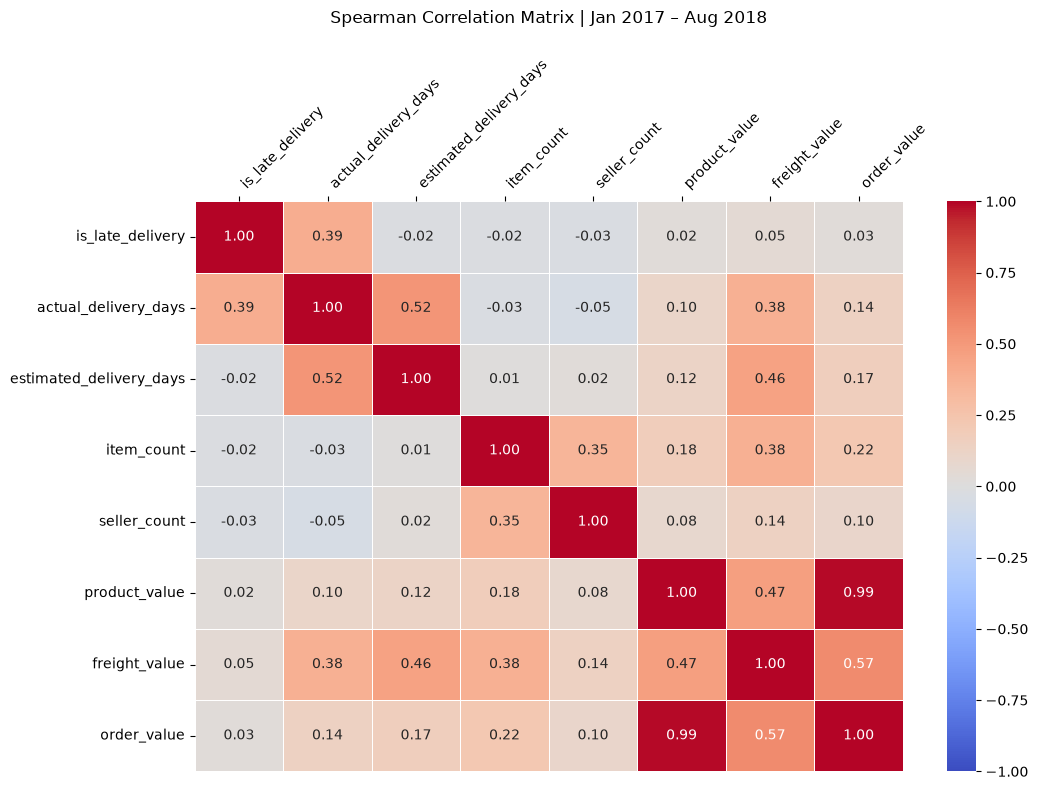

In [73]:
# Calculate Spearman correlations
corr_matrix = correlation_data.corr(method="spearman")

plt.figure(figsize=(11, 8))

ax = sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

# Move x-axis labels to the top
ax.xaxis.tick_top()
plt.xticks(rotation=45, ha="left")

plt.title("Spearman Correlation Matrix | Jan 2017 – Aug 2018", pad=25)
plt.tight_layout()
plt.show()

> More expensive transport is associated with a longer delivery time, but not necessarily with a higher risk of exceeding the promised deadline.

## Reasons for increasy late delivery rate in months

In [100]:
# Prepare order-level features for investigating delivery delays
query = """
WITH item_features AS (
    SELECT
        oi.order_id,
        CASE
            WHEN COUNT(DISTINCT oi.seller_id) = 1
            THEN MIN(oi.seller_id)
        END AS seller_id,
        CASE
            WHEN COUNT(DISTINCT p.product_category_name) = 1
            THEN MIN(p.product_category_name)
            ELSE 'multiple_or_unknown'
        END AS product_category,
        AVG(p.product_weight_g) AS avg_product_weight_g,
        SUM(
            p.product_length_cm * p.product_width_cm * p.product_height_cm
        ) AS total_product_volume_cm3
    FROM order_items oi
    LEFT JOIN products p ON oi.product_id = p.product_id
    GROUP BY oi.order_id
),
payment_features AS (
    SELECT
        order_id,
        CASE
            WHEN COUNT(DISTINCT payment_type) = 1
            THEN MIN(payment_type)
            ELSE 'multiple'
        END AS payment_type,
        MAX(payment_installments) AS max_installments
    FROM order_payments
    GROUP BY order_id
),
review_features AS (
    SELECT
        order_id,
        AVG(review_score) AS avg_review_score
    FROM order_reviews
    GROUP BY order_id
)
SELECT
    d.order_id,
    o.order_purchase_timestamp,
    o.order_approved_at,
    o.order_delivered_carrier_date,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date::date
        - o.order_purchase_timestamp::date AS estimated_delivery_days,
    d.delivery_days,
    d.is_late_delivery,
    d.has_date_sequence_issue,
    c.customer_state,
    sl.seller_state,
    f.seller_id,
    s.item_count,
    s.seller_count,
    s.product_value,
    s.freight_value,
    s.order_value,
    f.product_category,
    f.avg_product_weight_g,
    f.total_product_volume_cm3,
    pay.payment_type,
    pay.max_installments,
    r.avg_review_score
FROM vw_order_delivery d
JOIN orders o ON d.order_id = o.order_id
JOIN customers c ON d.customer_id = c.customer_id
LEFT JOIN vw_order_sales s ON d.order_id = s.order_id
LEFT JOIN item_features f ON d.order_id = f.order_id
LEFT JOIN sellers sl ON f.seller_id = sl.seller_id
LEFT JOIN payment_features pay ON d.order_id = pay.order_id
LEFT JOIN review_features r ON d.order_id = r.order_id
WHERE o.order_purchase_timestamp >= '2017-01-01'
    AND o.order_purchase_timestamp < '2018-09-01'
    AND d.is_late_delivery IS NOT NULL
"""

spike_data = pd.read_sql(
    query,
    engine,
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date"
    ]
)

In [101]:
# Add previously calculated shipping distances
spike_data = spike_data.merge(
    distance_data[["order_id", "distance_km"]],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Create purchase month and delivery stage durations
spike_data["month"] = (
    spike_data["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

spike_data["purchase_to_carrier_days"] = (
    spike_data["order_delivered_carrier_date"]
    - spike_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

spike_data["carrier_to_delivery_days"] = (
    spike_data["order_delivered_customer_date"]
    - spike_data["order_delivered_carrier_date"]
).dt.total_seconds() / 86400

# Exclude invalid date sequences from delivery stage calculations
spike_data.loc[
    spike_data["has_date_sequence_issue"],
    ["purchase_to_carrier_days", "carrier_to_delivery_days"]
] = np.nan

In [102]:
# Compare delivery performance around the months with elevated delays
months_to_check = ["2017-10", "2017-11", "2017-12", "2018-01", "2018-02", "2018-03", "2018-04"]

monthly_diagnostics = (
    spike_data[spike_data["month"].isin(months_to_check)]
    .groupby("month")
    .agg(
        orders=("order_id", "count"),
        late_rate_pct=("is_late_delivery", lambda x: x.mean() * 100),
        median_to_carrier_days=("purchase_to_carrier_days", "median"),
        median_transit_days=("carrier_to_delivery_days", "median"),
        median_estimated_days=("estimated_delivery_days", "median"),
        median_distance_km=("distance_km", "median"),
        median_freight_value=("freight_value", "median"),
        median_order_value=("order_value", "median")
    )
    .round(2)
)

print("Orders:", len(spike_data))
print("Unique orders:", spike_data["order_id"].nunique())

display(monthly_diagnostics)

Orders: 96203
Unique orders: 96203


,orders,late_rate_pct,median_to_carrier_days,median_transit_days,median_estimated_days,median_distance_km,median_freight_value,median_order_value
month,,,,,,,,
2017-10,4478,4.18,2.30,7.05,23.0,473.93,16.79,106.29
2017-11,7288,12.40,3.16,8.76,23.0,451.20,16.77,103.55
2017-12,5513,7.46,2.84,9.09,28.0,427.31,16.21,105.86
2018-01,7069,5.70,2.45,8.04,26.0,429.01,16.32,104.52
2018-02,6555,14.13,2.52,11.02,25.0,465.31,16.25,102.83
2018-03,7003,18.96,2.37,9.88,22.0,435.98,18.23,106.73
2018-04,6798,4.50,2.06,6.91,24.0,409.43,18.23,109.16


In [103]:
# Calculate delivery margin for each order
spike_data["delivery_margin_days"] = (spike_data["estimated_delivery_days"] - spike_data["delivery_days"])

# Compare delivery time distributions and margins by month
monthly_delivery_details = (
    spike_data[spike_data["month"].isin(months_to_check)]
    .groupby("month")
    .agg(
        median_delivery_days=("delivery_days", "median"),
        p90_delivery_days=("delivery_days", lambda x: x.quantile(0.90)),
        median_transit_days=("carrier_to_delivery_days", "median"),
        p90_transit_days=("carrier_to_delivery_days", lambda x: x.quantile(0.90)),
        median_delivery_margin=("delivery_margin_days", "median"),
        p10_delivery_margin=("delivery_margin_days", lambda x: x.quantile(0.10))
    )
    .round(2)
)

display(monthly_delivery_details)

,median_delivery_days,p90_delivery_days,median_transit_days,p90_transit_days,median_delivery_margin,p10_delivery_margin
month,,,,,,
2017-10,10.0,20.0,7.05,15.17,12.0,4.0
2017-11,13.0,27.0,8.76,21.95,10.0,-2.0
2017-12,13.0,28.0,9.09,23.13,14.0,2.0
2018-01,12.0,25.0,8.04,20.86,14.0,4.0
2018-02,14.0,31.0,11.02,26.81,10.0,-4.6
2018-03,13.0,32.0,9.88,28.22,8.0,-7.0
2018-04,9.0,21.0,6.91,18.13,13.0,5.0


> The increase in the Late Delivery Rate in November was linked to an overall deterioration in order fulfillment times, particularly during the transport phase.

> In February, the decline in on-time performance was primarily driven by longer transit times, especially among the slowest deliveries.

> The rise in delays in March may have stemmed from a combination of shorter estimated delivery timeframes and a deterioration in fulfillment times for the slowest deliveries.

In [104]:
# Identify interstate deliveries for single-seller orders
spike_data["interstate"] = (spike_data["customer_state"] != spike_data["seller_state"]).where(spike_data["seller_state"].notna())

# Compare order characteristics across months
monthly_features = (
    spike_data[spike_data["month"].isin(months_to_check)]
    .groupby("month")
    .agg(
        orders=("order_id", "count"),
        late_rate_pct=("is_late_delivery", lambda x: x.mean() * 100),
        interstate_pct=("interstate", lambda x: x.mean() * 100),
        multi_seller_pct=("seller_count", lambda x: (x > 1).mean() * 100),
        mean_item_count=("item_count", "mean"),
        median_product_weight_g=("avg_product_weight_g", "median"),
        median_product_volume_cm3=("total_product_volume_cm3", "median"),
        median_installments=("max_installments", "median")
    )
    .round(2)
)

display(monthly_features)

,orders,late_rate_pct,interstate_pct,multi_seller_pct,mean_item_count,median_product_weight_g,median_product_volume_cm3,median_installments
month,,,,,,,,
2017-10,4478,4.18,67.13,1.43,1.16,750.0,8000.0,2.0
2017-11,7288,12.40,66.39,1.28,1.16,792.0,8000.0,2.0
2017-12,5513,7.46,63.71,1.07,1.12,650.0,7500.0,2.0
2018-01,7069,5.70,64.20,1.44,1.14,700.0,7632.0,1.0
2018-02,6555,14.13,67.52,0.76,1.15,550.0,5832.0,1.0
2018-03,7003,18.96,63.11,1.29,1.14,600.0,6300.0,2.0
2018-04,6798,4.50,60.93,1.88,1.15,700.0,7408.0,1.0


> There is no strong evidence that the increases in the Late Delivery Rate resulted from a change in the characteristics of the products ordered or in the structure of orders.

> Increases in delays were more strongly associated with changes in lead times and transport than with the general characteristics of the orders.

In [108]:
# Calculate monthly delivery performance by customer state
state_monthly = (
    spike_data.groupby(["month", "customer_state"])
    .agg(
        orders=("order_id", "size"),
        late_orders=("is_late_delivery", "sum")
    )
    .reset_index()
)

state_monthly["late_rate_pct"] = (state_monthly["late_orders"] / state_monthly["orders"] * 100)

# Compare months with increased late delivery rates
month_pairs = [
    ("2017-10", "2017-11"),
    ("2018-01", "2018-02"),
    ("2018-02", "2018-03")
]

for previous, current in month_pairs:

    prev = state_monthly[state_monthly["month"] == previous].set_index("customer_state")

    curr = state_monthly[state_monthly["month"] == current].set_index("customer_state")

    comparison = curr.join(prev[["orders", "late_rate_pct"]], rsuffix="_prev")

    # Calculate changes in late delivery rates
    comparison["rate_change_pp"] = (comparison["late_rate_pct"] - comparison["late_rate_pct_prev"])

    # Estimate additional late orders relative to the previous month's rate
    comparison["excess_late_orders"] = (comparison["orders"] * comparison["rate_change_pp"] / 100)

    # Focus on states with sufficient observations in both months
    comparison = comparison[(comparison["orders"] >= 50) & (comparison["orders_prev"] >= 50)]

    print(f"\n{previous} → {current}")

    display(
        comparison[
            ["orders", "late_rate_pct",
             "rate_change_pp", "excess_late_orders"]
        ]
        .sort_values("excess_late_orders", ascending=False)
        .head(10)
        .round(2)
    )


2017-10 → 2017-11


C:\Users\marta\AppData\Local\Temp\ipykernel_29288\1728194587.py:26: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  comparison = curr.join(prev[["orders", "late_rate_pct"]], rsuffix="_prev")


,orders,late_rate_pct,rate_change_pp,excess_late_orders
customer_state,,,,
RJ,1012,25.99,19.11,193.37
SP,2898,6.97,3.72,107.81
MG,922,7.16,6.24,57.49
RS,409,12.71,10.66,43.62
SC,288,14.93,10.33,29.76
ES,168,20.24,15.24,25.60
CE,103,26.21,21.45,22.10
PR,365,8.77,5.74,20.94
GO,153,13.07,11.19,17.11



2018-01 → 2018-02


C:\Users\marta\AppData\Local\Temp\ipykernel_29288\1728194587.py:26: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  comparison = curr.join(prev[["orders", "late_rate_pct"]], rsuffix="_prev")


,orders,late_rate_pct,rate_change_pp,excess_late_orders
customer_state,,,,
RJ,879,34.02,20.96,184.21
SP,2632,7.33,3.90,102.76
MG,790,8.35,5.28,41.72
SC,254,24.02,14.05,35.68
BA,208,19.23,12.65,26.32
PR,335,8.96,7.34,24.58
CE,84,39.29,27.60,23.18
RS,363,13.22,5.05,18.33
GO,146,15.75,10.89,15.90



2018-02 → 2018-03


C:\Users\marta\AppData\Local\Temp\ipykernel_29288\1728194587.py:26: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  comparison = curr.join(prev[["orders", "late_rate_pct"]], rsuffix="_prev")


,orders,late_rate_pct,rate_change_pp,excess_late_orders
customer_state,,,,
MG,856,20.44,12.09,103.49
SP,2971,9.42,2.09,62.14
ES,133,41.35,29.27,38.93
BA,235,31.49,12.26,28.81
PA,67,50.75,38.47,25.77
RS,407,19.16,5.94,24.18
PR,369,13.28,4.32,15.96
MS,57,40.35,20.04,11.42
CE,93,50.54,11.25,10.46


**What does `excess_late_orders` mean?**
For example, if the previous month had a 5% late-order rate, and the current month saw 1,000 orders with a 15% late-order rate, then:
- Based on the previous rate, we would expect approximately 50 late orders.
- In reality, there were 150.
- `excess_late_orders` would be 100.
This represents a descriptive difference compared to the previous month; it is neither proof of causality nor a statistical forecast.

The 50-order threshold is used solely for the sake of a clear comparison. We do not remove any records from `spike_data`.

> The deterioration in timeliness was not limited to a single Brazilian state. However, in different months, various regions accounted for the largest share of the increase in the number of delays.

In [109]:
# Calculate monthly delivery performance by product category
category_monthly = (
    spike_data.groupby(["month", "product_category"])
    .agg(
        orders=("order_id", "size"),
        late_orders=("is_late_delivery", "sum")
    )
    .reset_index()
)

category_monthly["late_rate_pct"] = (
    category_monthly["late_orders"]
    / category_monthly["orders"] * 100
)

# Compare category performance between consecutive months
for previous, current in month_pairs:

    prev = category_monthly[category_monthly["month"] == previous].set_index("product_category")

    curr = category_monthly[category_monthly["month"] == current].set_index("product_category")

    comparison = curr.join(
        prev[["orders", "late_rate_pct"]].rename(
            columns={
                "orders": "orders_prev",
                "late_rate_pct": "late_rate_pct_prev"
            }
        ),
        how="inner"
    )

    # Calculate changes relative to the previous month's rate
    comparison["rate_change_pp"] = (comparison["late_rate_pct"] - comparison["late_rate_pct_prev"])

    comparison["excess_late_orders"] = (comparison["orders"] * comparison["rate_change_pp"] / 100)

    # Keep categories with at least 30 orders in both months
    comparison = comparison[(comparison["orders"] >= 30) & (comparison["orders_prev"] >= 30)]

    print(f"\n{previous} → {current}")

    display(
        comparison[
            ["orders", "late_rate_pct",
             "rate_change_pp", "excess_late_orders"]
        ]
        .sort_values("excess_late_orders", ascending=False)
        .head(10)
        .round(2)
    )


2017-10 → 2017-11


,orders,late_rate_pct,rate_change_pp,excess_late_orders
product_category,,,,
cama_mesa_banho,786,18.83,14.41,113.27
moveis_decoracao,526,16.54,12.33,64.83
esporte_lazer,537,9.50,6.61,35.51
brinquedos,437,11.90,7.79,34.06
ferramentas_jardim,421,12.59,7.85,33.05
beleza_saude,518,9.46,5.72,29.64
relogios_presentes,422,11.61,6.99,29.48
telefonia,340,12.94,8.40,28.55
automotivo,239,11.72,10.18,24.32



2018-01 → 2018-02


,orders,late_rate_pct,rate_change_pp,excess_late_orders
product_category,,,,
cama_mesa_banho,584,19.52,14.79,86.36
informatica_acessorios,789,14.20,9.98,78.78
esporte_lazer,570,14.39,8.40,47.88
relogios_presentes,304,19.08,13.75,41.80
beleza_saude,593,12.48,6.58,38.99
moveis_decoracao,326,16.56,11.12,36.24
eletronicos,299,16.39,11.06,33.07
telefonia,328,14.02,6.71,22.02
utilidades_domesticas,331,12.69,6.62,21.91



2018-02 → 2018-03


,orders,late_rate_pct,rate_change_pp,excess_late_orders
product_category,,,,
beleza_saude,604,23.84,11.36,68.63
esporte_lazer,641,19.81,5.43,34.79
automotivo,313,18.85,7.78,24.34
relogios_presentes,404,24.75,5.67,22.92
fashion_bolsas_e_acessorios,127,22.83,16.95,21.53
telefonia,316,20.57,6.55,20.68
perfumaria,179,20.67,10.25,18.35
cama_mesa_banho,642,21.65,2.13,13.68
multiple_or_unknown,169,13.02,7.55,12.76


> The problems occurred across a wide variety of categories.<br>
> `cama_mesa_banho (bedding, home textiles)` stands out in each of the three months.

In [110]:
# Calculate monthly delivery performance by seller
seller_monthly = (
    spike_data.dropna(subset=["seller_id"])
    .groupby(["month", "seller_id"])
    .agg(
        orders=("order_id", "size"),
        late_orders=("is_late_delivery", "sum")
    )
    .reset_index()
)

seller_monthly["late_rate_pct"] = (seller_monthly["late_orders"] / seller_monthly["orders"] * 100)

# Compare seller performance between consecutive months
for previous, current in month_pairs:

    prev = seller_monthly[seller_monthly["month"] == previous].set_index("seller_id")

    curr = seller_monthly[seller_monthly["month"] == current].set_index("seller_id")

    comparison = curr.join(
        prev[["orders", "late_rate_pct"]].rename(
            columns={
                "orders": "orders_prev",
                "late_rate_pct": "late_rate_pct_prev"
            }
        ),
        how="inner"
    )

    # Calculate changes in late delivery rates
    comparison["rate_change_pp"] = (comparison["late_rate_pct"] - comparison["late_rate_pct_prev"])

    comparison["excess_late_orders"] = (comparison["orders"] * comparison["rate_change_pp"] / 100)

    # Focus on sellers with at least 15 orders in both months
    comparison = comparison[(comparison["orders"] >= 15) & (comparison["orders_prev"] >= 15)]

    print(f"\n{previous} → {current}")
    print(f"Compared sellers: {len(comparison)}")

    display(
        comparison[
            ["orders", "late_orders", "late_rate_pct",
             "rate_change_pp", "excess_late_orders"]
        ]
        .sort_values("excess_late_orders", ascending=False)
        .head(10)
        .round(2)
    )


2017-10 → 2017-11
Compared sellers: 54


,orders,late_orders,late_rate_pct,rate_change_pp,excess_late_orders
seller_id,,,,,
4a3ca9315b744ce9f8e9374361493884,165,48,29.09,20.68,34.12
1025f0e2d44d7041d6cf58b6550e0bfa,97,28,28.87,26.49,25.69
ea8482cd71df3c1969d7b9473ff13abc,135,20,14.81,14.81,20.00
1f50f920176fa81dab994f9023523100,266,40,15.04,7.12,18.93
4869f7a5dfa277a7dca6462dcf3b52b2,84,21,25.00,21.88,18.38
7c67e1448b00f6e969d365cea6b010ab,66,22,33.33,24.71,16.31
cc419e0650a3c5ba77189a1882b7556a,197,21,10.66,8.26,16.27
1835b56ce799e6a4dc4eddc053f04066,43,16,37.21,37.21,16.00
3d871de0142ce09b7081e2b9d1733cb1,111,13,11.71,11.71,13.00



2018-01 → 2018-02
Compared sellers: 58


,orders,late_orders,late_rate_pct,rate_change_pp,excess_late_orders
seller_id,,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,87,31,35.63,32.82,28.55
4a3ca9315b744ce9f8e9374361493884,108,30,27.78,25.48,27.52
8b321bb669392f5163d04c59e235e066,163,30,18.40,16.56,27.00
cc419e0650a3c5ba77189a1882b7556a,92,18,19.57,17.64,16.23
1f50f920176fa81dab994f9023523100,125,18,14.40,12.34,15.42
955fee9216a65b617aa5c0531780ce60,84,16,19.05,17.30,14.53
1835b56ce799e6a4dc4eddc053f04066,49,11,22.45,20.18,9.89
218d46b86c1881d022bce9c68a7d4b15,54,10,18.52,16.14,8.71
8160255418d5aaa7dbdc9f4c64ebda44,44,10,22.73,17.17,7.56



2018-02 → 2018-03
Compared sellers: 68


,orders,late_orders,late_rate_pct,rate_change_pp,excess_late_orders
seller_id,,,,,
620c87c171fb2a6dd6e8bb4dec959fc6,60,27,45.00,33.89,20.33
ea8482cd71df3c1969d7b9473ff13abc,160,33,20.62,10.92,17.48
fa1c13f2614d7b5c4749cbc52fecda94,43,20,46.51,33.18,14.27
1f50f920176fa81dab994f9023523100,84,25,29.76,15.36,12.90
6560211a19b47992c3666cc44a7e94c0,73,14,19.18,16.36,11.94
c826c40d7b19f62a09e2d7c5e7295ee2,75,13,17.33,12.07,9.05
88460e8ebdecbfecb5f9601833981930,27,16,59.26,29.10,7.86
f7ba60f8c3f99e7ee4042fdef03b70c4,30,10,33.33,26.19,7.86
7a67c85e85bb2ce8582c35f2203ad736,58,13,22.41,11.45,6.64


In [111]:
# Analyze late delivery concentration among sellers
spike_months = ["2017-11", "2018-02", "2018-03"]

seller_concentration = []

for month in spike_months:

    # Include all single-seller orders in the selected month
    month_data = spike_data[(spike_data["month"] == month) & spike_data["seller_id"].notna()]

    # Identify sellers with the highest number of late orders
    seller_stats = (
        month_data.groupby("seller_id")
        .agg(
            orders=("order_id", "size"),
            late_orders=("is_late_delivery", "sum")
        )
        .sort_values("late_orders", ascending=False)
    )

    top10 = seller_stats.head(10)

    seller_concentration.append({
        "month": month,
        "total_sellers": len(seller_stats),
        "late_orders": seller_stats["late_orders"].sum(),
        "top10_order_share_pct": (
            top10["orders"].sum()
            / seller_stats["orders"].sum() * 100
        ),
        "top10_late_share_pct": (
            top10["late_orders"].sum()
            / seller_stats["late_orders"].sum() * 100
        )
    })

display(pd.DataFrame(seller_concentration).round(2))

,month,total_sellers,late_orders,top10_order_share_pct,top10_late_share_pct
0,2017-11,924,902,16.15,29.27
1,2018-02,923,925,14.17,21.51
2,2018-03,969,1324,15.19,19.79


> In November 2017, delays were more concentrated among the largest problematic sellers than in February and March 2018.

**Was the increase in delays concentrated on specific routes between Brazilian states?**

In [112]:
# Calculate monthly delivery performance by shipping route
route_monthly = (
    spike_data.dropna(subset=["seller_state"])
    .groupby(["month", "seller_state", "customer_state"])
    .agg(
        orders=("order_id", "size"),
        late_orders=("is_late_delivery", "sum")
    )
    .reset_index()
)

route_monthly["late_rate_pct"] = (route_monthly["late_orders"] / route_monthly["orders"] * 100)

# Compare changes in delivery performance by route
for previous, current in month_pairs:

    prev = route_monthly[route_monthly["month"] == previous].set_index(["seller_state", "customer_state"])

    curr = route_monthly[route_monthly["month"] == current].set_index(["seller_state", "customer_state"])

    comparison = curr.join(
        prev[["orders", "late_rate_pct"]].rename(
            columns={
                "orders": "orders_prev",
                "late_rate_pct": "late_rate_pct_prev"
            }
        ),
        how="inner"
    )

    # Calculate the change in late delivery rate
    comparison["rate_change_pp"] = (comparison["late_rate_pct"] - comparison["late_rate_pct_prev"])

    # Estimate excess late orders relative to the previous month's rate
    comparison["excess_late_orders"] = (comparison["orders"] * comparison["rate_change_pp"] / 100)

    # Focus on routes with at least 30 orders in both months
    comparison = comparison[(comparison["orders"] >= 30) & (comparison["orders_prev"] >= 30)]

    print(f"\n{previous} → {current}")

    display(
        comparison[
            ["orders", "late_rate_pct",
             "rate_change_pp", "excess_late_orders"]
        ]
        .sort_values("excess_late_orders", ascending=False)
        .head(10)
        .round(2)
    )


2017-10 → 2017-11


orders  late_rate_pct  rate_change_pp  \
seller_state customer_state                                          
SP           RJ                 698          32.23           24.15   
             SP                2153           7.34            3.35   
             MG                 584           8.56            7.74   
             RS                 279          13.98           10.97   
             SC                 201          18.41           13.82   
             ES                 119          26.89           21.34   
             PR                 244          11.89            8.21   
             GO                 107          17.76           15.23   
PR           SP                 190           7.89            7.89   
SP           CE                  77          23.38           18.83   

                             excess_late_orders  
seller_state customer_state                      
SP           RJ                          168.58  
             SP                           72.22  
             MG                           45.20  
             RS                           30.60  
             SC                           27.78  
             ES                           25.39  
             PR                           20.03  
             GO                           16.29  
PR           SP                           15.00  
SP           CE                           14.50


2018-01 → 2018-02


orders  late_rate_pct  rate_change_pp  \
seller_state customer_state                                          
SP           RJ                 563          39.43           26.53   
             SP                1874           7.95            4.93   
             MG                 502          10.36            7.27   
             RS                 243          17.70           11.57   
PR           RJ                 118          38.98           22.89   
SP           SC                 174          26.44           13.82   
             BA                 165          21.82           14.36   
             PR                 182          12.09            9.74   
             CE                  67          37.31           24.41   
             GO                 109          18.35           12.69   

                             excess_late_orders  
seller_state customer_state                      
SP           RJ                          149.39  
             SP                           92.39  
             MG                           36.51  
             RS                           28.12  
PR           RJ                           27.01  
SP           SC                           24.04  
             BA                           23.70  
             PR                           17.73  
             CE                           16.35  
             GO                           13.83


2018-02 → 2018-03


orders  late_rate_pct  rate_change_pp  \
seller_state customer_state                                          
SP           MG                 577          24.61           14.25   
             ES                 102          50.00           37.96   
RJ           SP                  82          43.90           27.02   
SP           SP                2294           8.89            0.94   
             PA                  51          52.94           42.07   
             BA                 173          34.10           12.29   
             RJ                 582          42.44            3.01   
             CE                  75          54.67           17.35   
RJ           MG                  44          34.09           22.98   
SP           RS                 265          21.51            3.81   

                             excess_late_orders  
seller_state customer_state                      
SP           MG                           82.23  
             ES                           38.72  
RJ           SP                           22.16  
SP           SP                           21.61  
             PA                           21.46  
             BA                           21.25  
             RJ                           17.51  
             CE                           13.01  
RJ           MG                           10.11  
SP           RS                           10.11

> route SP → RJ !

## Sales Performance Analysis

In [113]:
# Calculate monthly sales metrics for delivered orders
query = """
SELECT
    DATE_TRUNC('month', d.order_purchase_timestamp)::date AS month,
    COUNT(*) AS delivered_orders,
    SUM(s.product_value) AS merchandise_value,
    SUM(s.freight_value) AS freight_value,
    SUM(s.order_value) AS total_order_value,
    AVG(s.order_value) AS avg_order_value
FROM vw_order_delivery d
JOIN vw_order_sales s
    ON d.order_id = s.order_id
WHERE d.order_status = 'delivered'
    AND d.order_purchase_timestamp >= '2017-01-01'
    AND d.order_purchase_timestamp < '2018-09-01'
GROUP BY 1
ORDER BY 1
"""

monthly_sales = pd.read_sql(query, engine)

display(monthly_sales.round(2))

,month,delivered_orders,merchandise_value,freight_value,total_order_value,avg_order_value
0,2017-01-01,750,111798.36,15684.01,127482.37,169.98
1,2017-02-01,1653,234223.40,37015.92,271239.32,164.09
2,2017-03-01,2546,359198.85,55132.10,414330.95,162.74
3,2017-04-01,2303,340669.68,50142.72,390812.40,169.70
4,2017-05-01,3546,489338.25,77513.15,566851.40,159.86
5,2017-06-01,3135,421923.37,68127.00,490050.37,156.32
6,2017-07-01,3872,481604.52,84694.56,566299.08,146.25
7,2017-08-01,4193,554699.70,91132.66,645832.36,154.03
8,2017-09-01,4150,607399.67,93677.82,701077.49,168.93
9,2017-10-01,4478,648247.65,102869.36,751117.01,167.73


> The increase in sales value was primarily driven by a rise in the number of orders, rather than an increase in the average basket value.

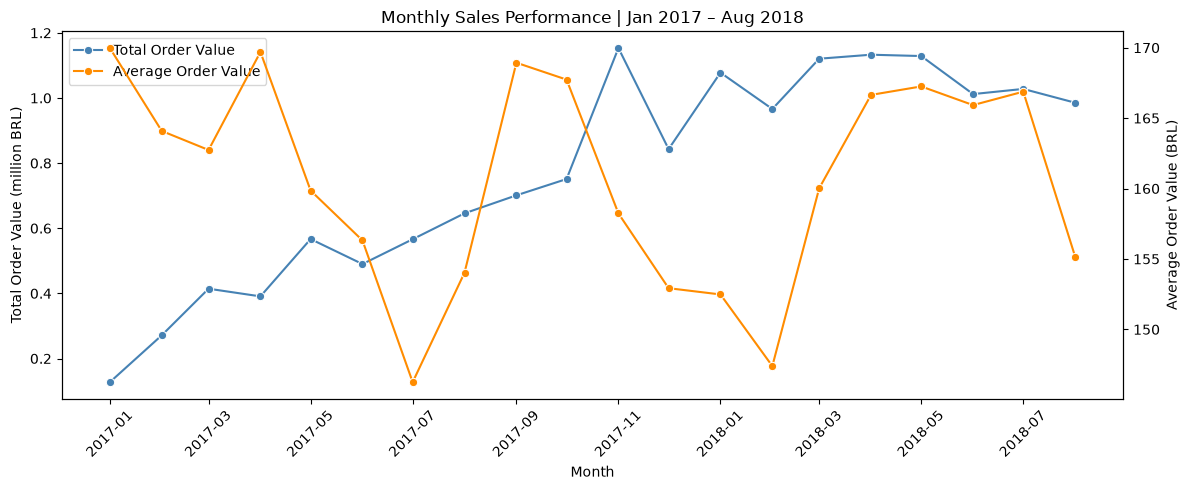

In [116]:
# Prepare monthly sales data for visualization
monthly_sales["month"] = pd.to_datetime(monthly_sales["month"])

fig, ax1 = plt.subplots(figsize=(12, 5))

# Plot monthly total order value
sns.lineplot(
    data=monthly_sales,
    x="month",
    y="total_order_value",
    color="steelblue",
    marker="o",
    label="Total Order Value",
    ax=ax1
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Total Order Value (BRL)")
ax1.tick_params(axis="x", rotation=45)

# Plot average order value on the second axis
ax2 = ax1.twinx()

sns.lineplot(
    data=monthly_sales,
    x="month",
    y="avg_order_value",
    color="darkorange",
    marker="o",
    label="Average Order Value",
    ax=ax2
)

ax2.set_ylabel("Average Order Value (BRL)")

# Combine both legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

if ax2.get_legend() is not None:
    ax2.get_legend().remove()



# Display total order value in millions of BRL
from matplotlib.ticker import FuncFormatter

ax1.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x / 1_000_000:.1f}")
)
ax1.set_ylabel("Total Order Value (million BRL)")



plt.title("Monthly Sales Performance | Jan 2017 – Aug 2018")
plt.tight_layout()
plt.show()

> The growth in the total value of orders was driven primarily by an increasing number of orders, rather than by an increase in the Average Order Value (AOV).

**Which product categories generated the highest sales value?**

In [117]:
# Calculate merchandise value by product category
query = """
SELECT
    COALESCE(p.product_category_name, 'unknown') AS product_category,
    COUNT(*) AS items_sold,
    COUNT(DISTINCT oi.order_id) AS orders,
    SUM(oi.price) AS merchandise_value,
    AVG(oi.price) AS avg_item_price
FROM order_items oi
JOIN orders o
    ON oi.order_id = o.order_id
JOIN products p
    ON oi.product_id = p.product_id
WHERE o.order_status = 'delivered'
    AND o.order_purchase_timestamp >= '2017-01-01'
    AND o.order_purchase_timestamp < '2018-09-01'
GROUP BY 1
ORDER BY merchandise_value DESC
"""

category_sales = pd.read_sql(query, engine)

# Calculate each category's contribution to merchandise value
category_sales["sales_share_pct"] = (category_sales["merchandise_value"] / category_sales["merchandise_value"].sum() * 100)

display(category_sales.head(10).round(2))

,product_category,items_sold,orders,merchandise_value,avg_item_price,sales_share_pct
0,beleza_saude,9422,8610,1229557.50,130.50,9.33
1,relogios_presentes,5855,5491,1163465.91,198.71,8.83
2,cama_mesa_banho,10945,9267,1022955.77,93.46,7.76
3,esporte_lazer,8414,7513,952840.40,113.24,7.23
4,informatica_acessorios,7632,6518,888055.59,116.36,6.74
5,moveis_decoracao,8095,6258,706237.17,87.24,5.36
6,utilidades_domesticas,6783,5734,614341.62,90.57,4.66
7,cool_stuff,3711,3552,609158.00,164.15,4.62
8,automotivo,4132,3802,577838.39,139.84,4.38
9,ferramentas_jardim,4263,3443,469135.40,110.05,3.56


> Sales were relatively concentrated within the most popular product categories, but no single category dominated the entire market.

In [125]:
# Translate product category names into English
category_names_en = {
    "beleza_saude": "Health & Beauty",
    "relogios_presentes": "Watches & Gifts",
    "cama_mesa_banho": "Bed, Bath & Table",
    "esporte_lazer": "Sports & Leisure",
    "informatica_acessorios": "Computers & Accessories",
    "moveis_decoracao": "Furniture & Decor",
    "utilidades_domesticas": "Housewares",
    "cool_stuff": "Cool Stuff",
    "automotivo": "Auto",
    "ferramentas_jardim": "Garden Tools",
    "brinquedos": "Toys",
    "bebe": "Baby",
    "perfumaria": "Perfumery",
    "telefonia": "Telephony",
    "moveis_escritorio": "Office Furniture",
    "papelaria": "Stationery",
    "pet_shop": "Pet Shop",
    "eletronicos": "Electronics",
    "fashion_bolsas_e_acessorios": "Fashion Bags & Accessories",
    "consoles_games": "Consoles & Games",
    "eletrodomesticos": "Home Appliances",
    "malas_acessorios": "Luggage & Accessories"
}

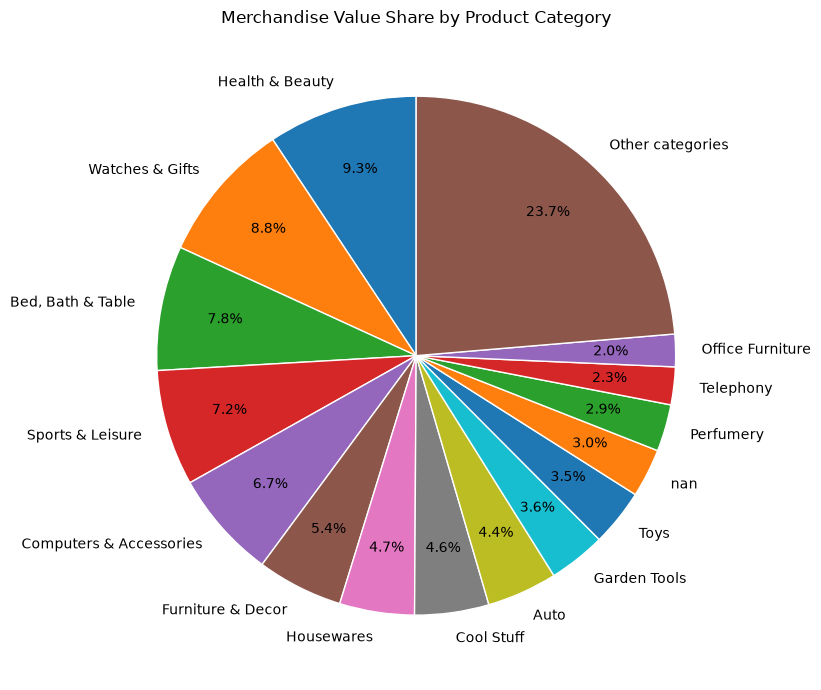

In [126]:
# Prepare top 15 categories and group the remaining categories
top15 = category_sales.head(15)

values = list(top15["merchandise_value"]) + [
    category_sales.iloc[15:]["merchandise_value"].sum()
]

labels = list(top15["category_en"]) + ["Other categories"]

# Plot merchandise value distribution
fig, ax = plt.subplots(figsize=(9, 7))

ax.pie(
    values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.75,
    wedgeprops={"edgecolor": "white"}
)

ax.set_title("Merchandise Value Share by Product Category")

plt.tight_layout()
plt.show()

## Customer Satisfaction Analysis

In [127]:
# Compare customer ratings by delivery status
review_summary = (
    spike_data.groupby("is_late_delivery")
    .agg(
        orders=("order_id", "size"),
        reviewed_orders=("avg_review_score", "count"),
        mean_review_score=("avg_review_score", "mean"),
        median_review_score=("avg_review_score", "median"),
        low_review_rate_pct=(
            "avg_review_score",
            lambda x: (x.dropna() <= 2).mean() * 100
        )
    )
)

# Calculate review coverage
review_summary["review_coverage_pct"] = (review_summary["reviewed_orders"] / review_summary["orders"] * 100)

# Rename delivery status for readability
review_summary.index = review_summary.index.map({
    False: "On Time",
    True: "Late"
})

display(review_summary.round(2))

,orders,reviewed_orders,mean_review_score,median_review_score,low_review_rate_pct,review_coverage_pct
is_late_delivery,,,,,,
On Time,89672,89182,4.29,5.0,9.21,99.45
Late,6531,6378,2.27,1.0,62.35,97.66


`low_review_rate_pct`	Percentage of ratings of 2 or lower

`review_coverage_pct`	Percentage of orders for which we have a rating

> a very strong correlation between delivery punctuality and customer rating

In [128]:
# Select late deliveries
late_reviews = spike_data[spike_data["is_late_delivery"]].copy()

# Calculate the number of days past the estimated delivery date
late_reviews["days_late"] = (late_reviews["delivery_days"] - late_reviews["estimated_delivery_days"])

# Check for inconsistencies between the late flag and calculated delay
print("Late orders with non-positive delay:", (late_reviews["days_late"] <= 0).sum())

# Keep positive delays for the duration-based analysis
late_reviews = late_reviews[late_reviews["days_late"] > 0].copy()

# Group orders by delay duration
late_reviews["delay_bucket"] = pd.cut(
    late_reviews["days_late"],
    bins=[0, 2, 7, 14, float("inf")],
    labels=["1–2 days", "3–7 days", "8–14 days", "15+ days"]
)

# Compare customer ratings across delay durations
delay_review_summary = (
    late_reviews.groupby("delay_bucket", observed=True)
    .agg(
        orders=("order_id", "size"),
        reviewed_orders=("avg_review_score", "count"),
        mean_review_score=("avg_review_score", "mean"),
        median_review_score=("avg_review_score", "median"),
        low_review_rate_pct=(
            "avg_review_score",
            lambda x: (x.dropna() <= 2).mean() * 100
        )
    )
    .round(2)
)

display(delay_review_summary)

Late orders with non-positive delay: 0


,orders,reviewed_orders,mean_review_score,median_review_score,low_review_rate_pct
delay_bucket,,,,,
1–2 days,1369,1355,3.51,4.0,25.54
3–7 days,2302,2244,2.23,1.0,63.77
8–14 days,1478,1446,1.67,1.0,80.08
15+ days,1382,1333,1.73,1.0,78.17


In [130]:
from scipy.stats import spearmanr

# Keep orders with customer reviews
reviews = spike_data.dropna(subset=["avg_review_score"]).copy()

# Correlation between late delivery status and review score
rho_status, p_status = spearmanr(reviews["is_late_delivery"].astype(int), reviews["avg_review_score"])

# Analyze delay duration among late deliveries
late_reviews = reviews[reviews["is_late_delivery"]].copy()

late_reviews["days_late"] = (late_reviews["delivery_days"] - late_reviews["estimated_delivery_days"])

late_reviews = late_reviews[late_reviews["days_late"] > 0]

# Correlation between delay duration and review score
rho_duration, p_duration = spearmanr(late_reviews["days_late"], late_reviews["avg_review_score"])

print(f"Late Delivery vs Review Score: rho = {rho_status:.3f}, p = {p_status:.5f}")
print(f"Days Late vs Review Score: rho = {rho_duration:.3f}, p = {p_duration:.5f}")

Late Delivery vs Review Score: rho = -0.312, p = 0.00000
Days Late vs Review Score: rho = -0.401, p = 0.00000


> Delays are strongly linked to negative customer ratings, and we observe a particularly sharp decline in satisfaction when delays exceed two days.


### Customer Satisfaction: Monthly Trends

In [135]:
# Calculate monthly customer satisfaction metrics by delivery status
monthly_reviews = (
    spike_data.dropna(subset=["avg_review_score"])
    .groupby(["month", "is_late_delivery"])
    .agg(
        reviewed_orders=("order_id", "size"),
        mean_review_score=("avg_review_score", "mean"),
        low_review_rate_pct=(
            "avg_review_score",
            lambda x: (x <= 2).mean() * 100
        )
    )
    .reset_index()
)

# Add readable delivery status labels
monthly_reviews["delivery_status"] = (monthly_reviews["is_late_delivery"].map({False: "On Time", True: "Late"}))

# Compare monthly results between delivery groups
monthly_review_comparison = monthly_reviews.pivot(
    index="month",
    columns="delivery_status",
    values=[
        "reviewed_orders",
        "mean_review_score",
        "low_review_rate_pct"
    ]
)

# Calculate monthly Spearman correlation between late delivery and review score
monthly_correlations = pd.Series({
    month: spearmanr(
        group["is_late_delivery"].astype(int),
        group["avg_review_score"]
    ).statistic
    for month, group in (
        spike_data.dropna(subset=["avg_review_score"])
        .groupby("month")
    )
})

# Add correlations to the existing monthly comparison table
monthly_review_comparison[("spearman_rho", "Late vs Review")] = (monthly_correlations)

display(monthly_review_comparison.round(3))

reviewed_orders         mean_review_score          \
delivery_status            Late On Time              Late On Time   
month                                                               
2017-01                    21.0   720.0             1.952   4.265   
2017-02                    42.0  1601.0             2.143   4.257   
2017-03                   113.0  2414.0             2.389   4.272   
2017-04                   147.0  2143.0             2.466   4.252   
2017-05                    99.0  3418.0             2.737   4.282   
2017-06                    92.0  3019.0             2.435   4.277   
2017-07                   105.0  3737.0             2.238   4.315   
2017-08                   121.0  4044.0             2.653   4.361   
2017-09                   177.0  3941.0             2.593   4.343   
2017-10                   179.0  4267.0             2.547   4.275   
2017-11                   887.0  6350.0             2.197   4.239   
2017-12                   401.0  5060.0             2.115   4.246   
2018-01                   396.0  6617.0             2.013   4.234   
2018-02                   912.0  5595.0             1.917   4.202   
2018-03                  1296.0  5652.0             2.070   4.213   
2018-04                   297.0  6455.0             2.232   4.297   
2018-05                   437.0  6285.0             2.757   4.339   
2018-06                    71.0  6001.0             2.310   4.331   
2018-07                   200.0  5918.0             2.755   4.371   
2018-08                   385.0  5945.0             2.995   4.396   

                low_review_rate_pct           spearman_rho  
delivery_status                Late On Time Late vs Review  
month                                                       
2017-01                      71.429  10.278         -0.249  
2017-02                      69.048   9.557         -0.202  
2017-03                      58.407   9.031         -0.244  
2017-04                      58.503   9.659         -0.271  
2017-05                      49.495   8.865         -0.154  
2017-06                      56.522   9.208         -0.199  
2017-07                      62.857   8.429         -0.211  
2017-08                      52.893   8.086         -0.182  
2017-09                      53.107   8.272         -0.237  
2017-10                      54.190   9.210         -0.209  
2017-11                      64.600   9.811         -0.403  
2017-12                      68.579  10.119         -0.330  
2018-01                      70.202  10.292         -0.310  
2018-02                      72.259  10.617         -0.466  
2018-03                      67.670  10.456         -0.493  
2018-04                      62.626   9.404         -0.268  
2018-05                      46.682   8.258         -0.263  
2018-06                      60.563   9.382         -0.139  
2018-07                      50.000   8.297         -0.186  
2018-08                      42.597   7.401         -0.227

> Ratings for deliveries remained stable from month to month.

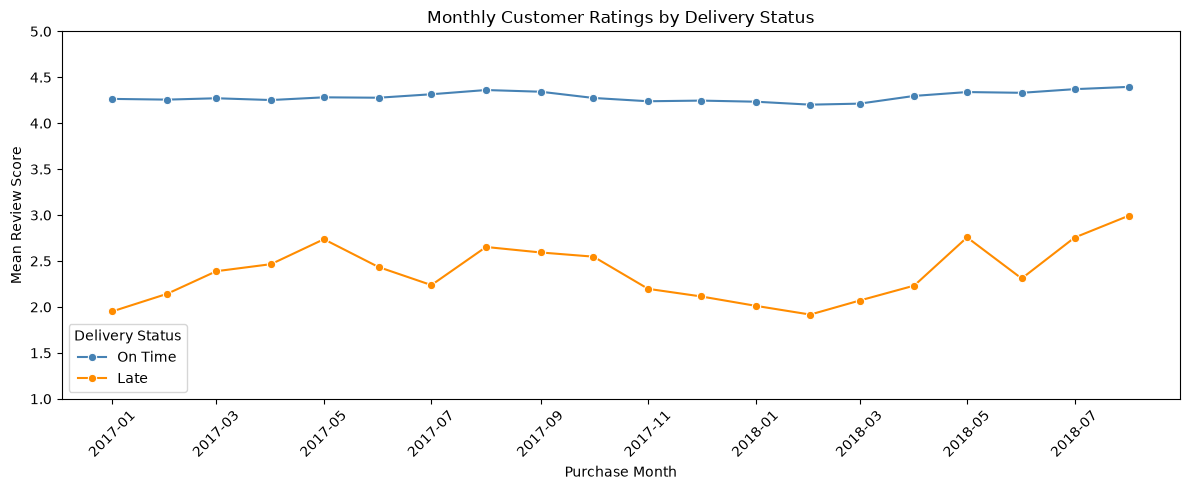

In [136]:
# Prepare monthly customer ratings for visualization
review_plot = monthly_reviews.copy()
review_plot["month"] = pd.to_datetime(review_plot["month"])

# Plot average review scores by delivery status
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=review_plot,
    x="month",
    y="mean_review_score",
    hue="delivery_status",
    hue_order=["On Time", "Late"],
    palette={"On Time": "steelblue", "Late": "darkorange"},
    marker="o"
)

plt.title("Monthly Customer Ratings by Delivery Status")
plt.xlabel("Purchase Month")
plt.ylabel("Mean Review Score")
plt.ylim(1, 5)
plt.xticks(rotation=45)
plt.legend(title="Delivery Status")

plt.tight_layout()
plt.show()

# Key Findings and Business Implications

## 1. Delivery Performance

Delivery times were right-skewed, with a median of 10 days and a mean of approximately 12.5 days. Estimated delivery windows were generally longer than actual delivery times, although a subset of orders experienced substantial delays. Geographical distance was moderately associated with actual delivery time (Spearman ρ = 0.543). Interstate deliveries generally took longer than deliveries within the same state. Late delivery rates increased substantially in November 2017 (12.40%), February 2018 (14.13%), and March 2018 (18.96%). These spikes were associated with longer transit times, changes in estimated delivery windows, and deteriorating performance on specific shipping routes, particularly São Paulo → Rio de Janeiro. The observed patterns suggest that delivery performance varied across periods and shipping routes rather than being driven by a single identifiable factor.

## 2. Sales Performance

Monthly order value increased considerably throughout 2017, reaching approximately BRL 1.15 million in November. During 2018, monthly order value remained relatively stable at around BRL 1 million.
Average order value fluctuated within a comparatively narrow range, suggesting that changes in total order value were primarily associated with order volume.
The five largest product categories accounted for approximately 40% of total merchandise value, indicating a diversified sales mix with moderate concentration among leading categories.

## 3. Customer Satisfaction

Delivery punctuality was strongly associated with customer satisfaction.
On-time deliveries received an average review score of 4.29, compared with 2.27 for late deliveries. Low ratings (1–2 stars) occurred in 9.21% of on-time deliveries and 62.35% of late deliveries.
Among delayed orders, longer delays were associated with lower customer ratings (Spearman ρ = −0.401, p < 0.001). The proportion of low ratings increased particularly sharply when delays exceeded two days.
On-time delivery ratings remained relatively stable throughout the observation period, while delayed deliveries consistently received substantially lower ratings.

## 4. Business Implications

The findings support prioritizing delivery reliability as a key operational metric.
Monitoring should extend beyond the overall late delivery rate to include delay duration, shipping-route performance, and changes in transit times.
Routes with recurring delivery problems, such as São Paulo → Rio de Janeiro, warrant closer operational investigation.
Reducing severe delays may be particularly valuable for customer experience, given their strong association with negative reviews.

## 5. Limitations

The analysis is observational and does not establish causal relationships.
Geographical distances were approximated using ZIP-code-prefix coordinates and represent straight-line distances rather than actual transport routes.
Some geographical and seller-level analyses were restricted to single-seller orders. Orders with missing information were excluded where necessary.
Customer review scores may reflect factors beyond delivery performance, including product quality, communication, and other aspects of the purchasing experience.